# 01 · Bi-Modal Feature Extraction (paper §4.1, Eq. 1–3)

In [1]:
import os
os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")      # Windows: avoid the duplicate-OpenMP abort that kills the kernel
import faulthandler; faulthandler.enable()          # prints a native traceback to the Jupyter log if the kernel dies
import sys, json, time
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch, torch.nn.functional as F
from torch.utils.data import DataLoader
from cmucl_nb import common as C, views as V

cfg = C.load_config(); args = C.as_args(cfg); device = C.get_device(cfg)
C.set_cpu_threads()                          # leave some CPU cores free so the laptop stays responsive
C.fetch_official_code()                      # official repo -> ./third_party/CMUCL (not copied into this repo)
from model import CMUCL, tokenize            # official model + tokenizer
from data import DataHelper                  # official neighbour sampler

ds = C.load_saved_dataset()
x = torch.from_numpy(ds["feats"]).to(device)
edge_index = torch.from_numpy(ds["edge_index"]).to(device)
labels, texts = ds["labels"], ds["texts"]
print(f"dataset={cfg['dataset']}  device={device}  torch threads={torch.get_num_threads()}  nodes={ds['n']} (of {cfg.get('n_full')})  anomalies={labels.sum()}")

dataset=Citeseer  device=cpu  torch threads=4  nodes=384 (of 3186)  anomalies=19


In [2]:
C.setup_seed(cfg["seed"])                    # same order as official main_train.py: seed -> model
model = CMUCL(args).to(device); C.prepare_model(model)   # CPU: thread limit + gradient checkpointing (same maths, far less RAM)
model.eval()
n_params = lambda m: sum(p.numel() for p in m.parameters())
print(f"transformer: {n_params(model.transformer)/1e6:.2f}M | token emb: {model.token_embedding.weight.numel()/1e6:.2f}M | GCN: {n_params(model.gnn)/1e6:.3f}M")
print(f"text encoder: {args.transformer_layers} layers x width {args.transformer_width}, {args.transformer_heads} heads | GCN: {args.gnn_layers} layers, hidden {args.gnn_hid}")

transformer: 37.83M | token emb: 25.30M | GCN: 0.246M
text encoder: 12 layers x width 512, 8 heads | GCN: 2 layers, hidden 128


<div dir="rtl" style="text-align:right">

## ۱) Tokenization و انتخاب توکن EOS

</div>

text      : Decomposition in Data Mining: An Industrial Case Study Data mining offers tools for discovery of relationships, patterns ...
first ids : [49406, 561, 17510, 530, 2281, 8473, 281, 550, 7520, 2068, 3123, 2281]
first toks: ['<|startoftext|>', 'de', 'composition</w>', 'in</w>', 'data</w>', 'mining</w>', ':</w>', 'an</w>', 'industrial</w>', 'case</w>', 'study</w>', 'data</w>']
EOS position (argmax) = 127, id = 49407; padding after it: 0 zeros
(tokenised 200 texts in 1.5s)
token length: mean 194, median 197; truncated at context_length=128: 90.0%


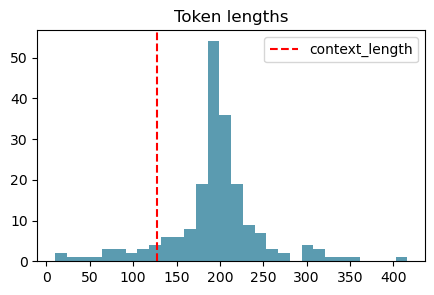

In [3]:
from simple_tokenizer import SimpleTokenizer
tok = SimpleTokenizer()
i0 = int(np.where(labels == 0)[0][0])
ids = tokenize([texts[i0]], context_length=args.context_length)[0]
eot = int(ids.argmax())
print("text      :", str(texts[i0])[:120], "...")
print("first ids :", ids[:12].tolist())
print("first toks:", [tok.decoder[t] for t in ids[:12].tolist()])
print(f"EOS position (argmax) = {eot}, id = {int(ids[eot])}; padding after it: {int((ids == 0).sum())} zeros")

t0 = time.time(); sample = np.random.RandomState(0).choice(ds["n"], min(200, ds["n"]), replace=False)
lens = np.array([len(tok.encode(str(texts[i]))) + 2 for i in sample])
print(f"(tokenised {len(sample)} texts in {time.time()-t0:.1f}s)")
print(f"token length: mean {lens.mean():.0f}, median {np.median(lens):.0f}; truncated at context_length={args.context_length}: {100*(lens > args.context_length).mean():.1f}%")
plt.figure(figsize=(5, 3)); plt.hist(lens, bins=30, color="#5b9bb0"); plt.axvline(args.context_length, color="r", ls="--", label="context_length"); plt.legend()
plt.title("Token lengths"); C.savefig("01_token_lengths"); plt.show()

<div dir="rtl" style="text-align:right">

## ۲) Text encoder، گام‌به‌گام (Eq. 1)

</div>

In [4]:
B = 8
batch_ids = tokenize(texts[:B].tolist(), context_length=args.context_length).to(device)
with torch.no_grad():
    e = model.token_embedding(batch_ids);                print("token_embedding          ", tuple(e.shape))
    e = e + model.positional_embedding;                  print("+ positional_embedding   ", tuple(e.shape))
    e = model.transformer(e.permute(1, 0, 2)).permute(1, 0, 2); print(f"after {args.transformer_layers} transformer blocks", tuple(e.shape), "(causal mask)")
    e = model.ln_final(e);                               print("ln_final                 ", tuple(e.shape))
    e = e[torch.arange(B), batch_ids.argmax(dim=-1)];    print("pick EOS token           ", tuple(e.shape))
    hT_manual = e @ model.text_projection;               print("@ text_projection  -> h^T", tuple(hT_manual.shape))
    hT_official = model.encode_text(batch_ids)
assert torch.allclose(hT_manual, hT_official, atol=1e-5); print("OK: identical to model.encode_text")

token_embedding           (8, 128, 512)
+ positional_embedding    (8, 128, 512)
after 12 transformer blocks (8, 128, 512) (causal mask)
ln_final                  (8, 128, 512)
pick EOS token            (8, 512)
@ text_projection  -> h^T (8, 128)
OK: identical to model.encode_text


<div dir="rtl" style="text-align:right">

## ۳) Graph encoder، گام‌به‌گام (Eq. 2)

</div>

In [5]:
import torch.nn.functional as F
g = model.gnn
with torch.no_grad():
    stages = {"input (768-d)": x}
    h = g.proj(x); stages["proj"] = h
    for k, conv in enumerate(g.conv_layers):
        res = h; h = F.leaky_relu(conv(h, edge_index) + res); stages[f"GCN block {k+1}"] = h
    hG_manual = g.act(g.linear(h)) + g.act(g.res(x)); stages["output h^G"] = hG_manual
    _, hG_all = model.encode_graph(torch.arange(ds["n"]), x, edge_index)
assert torch.allclose(hG_manual, hG_all, atol=1e-5); print("OK: identical to model.encode_graph")
print(pd.DataFrame({k: {"dim": v.shape[1], "mean ||h||": float(v.norm(dim=1).mean())} for k, v in stages.items()}).T)

OK: identical to model.encode_graph
                 dim  mean ||h||
input (768-d)  768.0   27.740389
proj           128.0    6.473550
GCN block 1    128.0    6.202154
GCN block 2    128.0    7.847303
output h^G     128.0    6.181196


<div dir="rtl" style="text-align:right">

## ۴) Context-level embedding (Eq. 3) — و یک تفاوت مهم کد با مقاله


</div>

lenth of dataset 384
s_n: (64,) | sampled neighbours t_n: (64, 3)
nodes whose ONLY neighbour is themselves (self-loop): 77.9% -> their context embedding is computed from the node itself
cos(context from 3 sampled neighbours, context from ALL neighbours): mean 0.980, min 0.734


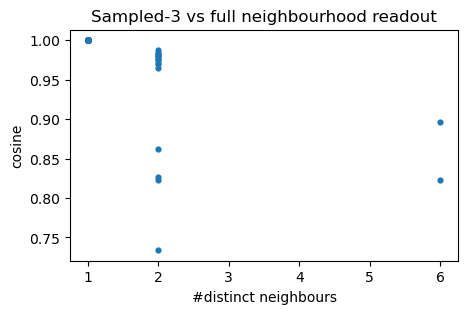

In [6]:
Data = DataHelper(ds["edge_index"], args)            # official sampler (also builds the neighbour lists)
C.setup_seed(cfg["seed"])
loader = DataLoader(Data, batch_size=args.batch_size, shuffle=True, num_workers=0)
batch = next(iter(loader)); s_n, t_n = batch["s_n"], batch["t_n"]
print("s_n:", tuple(s_n.shape), "| sampled neighbours t_n:", tuple(t_n.shape))

with torch.no_grad():
    hG_sampled = hG_all[t_n.numpy().reshape(-1)].reshape(len(s_n), args.neigh_num, -1).mean(1)               # code
    hG_allnb = torch.stack([hG_all[Data.neighs[int(i)]].mean(0) for i in s_n])                               # paper Eq.3
cos = F.cosine_similarity(hG_sampled, hG_allnb, dim=-1).cpu().numpy()
deg_b = np.array([len(set(Data.neighs[int(i)])) for i in s_n])
only_self = np.mean([set(Data.neighs[int(i)]) == {int(i)} for i in Data.idx])
print(f"nodes whose ONLY neighbour is themselves (self-loop): {100*only_self:.1f}% -> their context embedding is computed from the node itself")
print(f"cos(context from 3 sampled neighbours, context from ALL neighbours): mean {cos.mean():.3f}, min {cos.min():.3f}")
plt.figure(figsize=(5, 3)); plt.scatter(deg_b, cos, s=12); plt.xlabel("#distinct neighbours"); plt.ylabel("cosine")
plt.title("Sampled-3 vs full neighbourhood readout"); C.savefig("01_context_sampling"); plt.show()

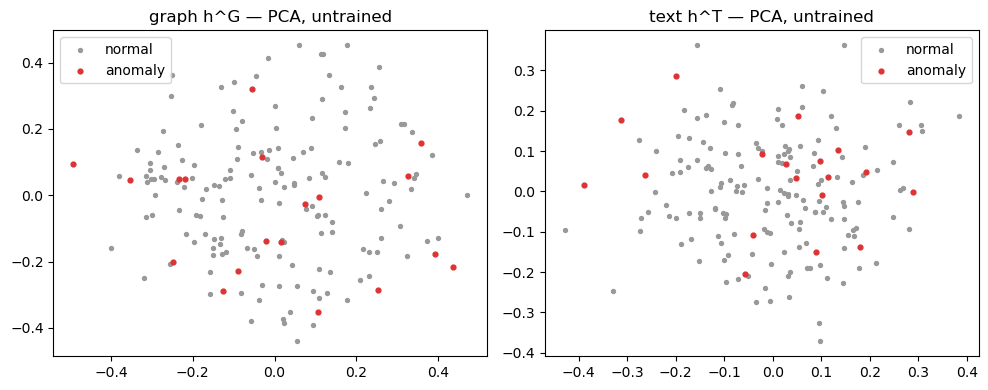

In [7]:
from sklearn.decomposition import PCA
rng = np.random.RandomState(0)
anom = np.where(labels == 1)[0]; norm_ = np.where(labels == 0)[0]
idx = np.r_[rng.choice(anom, min(len(anom), 40), replace=False), rng.choice(norm_, min(len(norm_), 160), replace=False)]
t0 = time.time()
with torch.no_grad():
    hT_idx = torch.cat([model.encode_text(tokenize(texts[idx[i:i+64]].tolist(), context_length=args.context_length).to(device))
                        for i in range(0, len(idx), 64)])
    hG_idx = hG_all[idx]
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a, Z, name in zip(ax, [hG_idx, hT_idx], ["graph h^G", "text h^T"]):
    P = PCA(2).fit_transform(F.normalize(Z, dim=-1).cpu().numpy())
    a.scatter(*P[labels[idx] == 0].T, s=8, c="#999", label="normal"); a.scatter(*P[labels[idx] == 1].T, s=12, c="#d33", label="anomaly")
    a.set_title(f"{name} — PCA, untrained"); a.legend()
plt.tight_layout(); C.savefig("01_embeddings_untrained"); plt.show()

In [8]:
# Save a fixed *probe batch* + the initial weights: notebooks 02-04 reuse them so every stage looks at the same nodes.
torch.save(dict(s_n=s_n, t_n=t_n), C.ART / "probe.pt")
torch.save(model.state_dict(), C.ART / "init_state.pt")
print("saved probe.pt + init_state.pt")

saved probe.pt + init_state.pt
